# PCA Analysis: INPUT vs UDNAIP Conditions

This notebook performs Principal Component Analysis (PCA) on bigwig files to compare INPUT and UDNAIP conditions across different experiments (3d7_rep1, 3d7_rep2, DMSO, RAPA).

## 1. Import Required Libraries

In [1]:
import pyBigWig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from matplotlib.lines import Line2D

# Set plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)

## 2. Define BigWig Files and Parse Metadata

In [ ]:
# Define the bigwig files (located in data/ directory)
bigwig_files = [
    "../data/3d7_rep1.Plasmodium.INPUTcorrect.bin100bp.RPGC.bw",
    "../data/3d7_rep1.Plasmodium.UDNAIPcorrect.bin100bp.RPGC.bw",
    "../data/3d7_rep2.Plasmodium.INPUT.bin100bp.RPGC.bw",
    "../data/3d7_rep2.Plasmodium.UDNAIP.bin100bp.RPGC.bw",
    "../data/DMSO.INPUT.bin100bp.RPGC.bw",
    "../data/DMSO.UDNAIP.bin100bp.RPGC.bw",
    "../data/RAPA.INPUT.bin100bp.RPGC.bw",
    "../data/RAPA.UDNAIP.bin100bp.RPGC.bw",
]

def parse_filename(filename):
    """Extract experiment and condition from filename."""
    base = Path(filename).stem
    
    if "3d7_rep1" in base:
        experiment = "3d7_rep1"
    elif "3d7_rep2" in base:
        experiment = "3d7_rep2"
    elif "DMSO" in base:
        experiment = "DMSO"
    elif "RAPA" in base:
        experiment = "RAPA"
    else:
        experiment = "Unknown"
    
    condition = "UDNAIP" if "UDNAIP" in base else "INPUT"
    return experiment, condition

# Test parsing
for bw_file in bigwig_files:
    exp, cond = parse_filename(bw_file)
    print(f"{bw_file}: {exp} - {cond}")

3d7_rep1.Plasmodium.INPUTcorrect.bin100bp.RPGC.bw: 3d7_rep1 - INPUT
3d7_rep1.Plasmodium.UDNAIPcorrect.bin100bp.RPGC.bw: 3d7_rep1 - UDNAIP
3d7_rep2.Plasmodium.INPUT.bin100bp.RPGC.bw: 3d7_rep2 - INPUT
3d7_rep2.Plasmodium.UDNAIP.bin100bp.RPGC.bw: 3d7_rep2 - UDNAIP
DMSO.INPUT.bin100bp.RPGC.bw: DMSO - INPUT
DMSO.UDNAIP.bin100bp.RPGC.bw: DMSO - UDNAIP
RAPA.INPUT.bin100bp.RPGC.bw: RAPA - INPUT
RAPA.UDNAIP.bin100bp.RPGC.bw: RAPA - UDNAIP


## 3. Extract Signals from BigWig Files

In [9]:
def extract_signals(bw_file, bin_size=100):
    """Extract signal values from bigwig file in bins."""
    bw = pyBigWig.open(bw_file)
    signals = []
    
    for chrom in sorted(bw.chroms().keys()):
        chrom_length = bw.chroms()[chrom]
        for start in range(0, chrom_length, bin_size):
            end = min(start + bin_size, chrom_length)
            try:
                val = bw.stats(chrom, start, end, type="mean")
                signals.append(val[0] if val and val[0] is not None else 0.0)
            except:
                signals.append(0.0)
    
    bw.close()
    return np.array(signals)

## 4. Prepare and Standardize Data

In [10]:
# Load signals from all bigwig files
data = {}
for bw_file in bigwig_files:
    exp_name, condition = parse_filename(bw_file)
    key = f"{exp_name}_{condition}"
    signals = extract_signals(bw_file)
    data[key] = signals
    print(f"Loaded {key}: {len(signals)} bins")

# Find maximum length and pad all signals
max_len = max(len(v) for v in data.values())
print(f"\nPadding all signals to length: {max_len}")

data_padded = {}
for key, signals in data.items():
    padded = np.concatenate([signals, np.zeros(max_len - len(signals))])
    data_padded[key] = padded

# Create matrix for PCA
X = np.array([data_padded[key] for key in sorted(data_padded.keys())])
X = np.nan_to_num(X, nan=0, posinf=0, neginf=0)

# Standardize features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\nData matrix shape: {X_scaled.shape}")
print("Data preparation complete!")

Loaded 3d7_rep1_INPUT: 233337 bins
Loaded 3d7_rep1_UDNAIP: 233337 bins
Loaded 3d7_rep2_INPUT: 233337 bins
Loaded 3d7_rep2_UDNAIP: 233337 bins
Loaded DMSO_INPUT: 233337 bins
Loaded DMSO_UDNAIP: 233337 bins
Loaded RAPA_INPUT: 233337 bins
Loaded RAPA_UDNAIP: 233337 bins

Padding all signals to length: 233337

Data matrix shape: (8, 233337)
Data preparation complete!


## 5. Perform PCA Analysis

## 5a. Elbow Analysis to Determine Optimal Number of Components

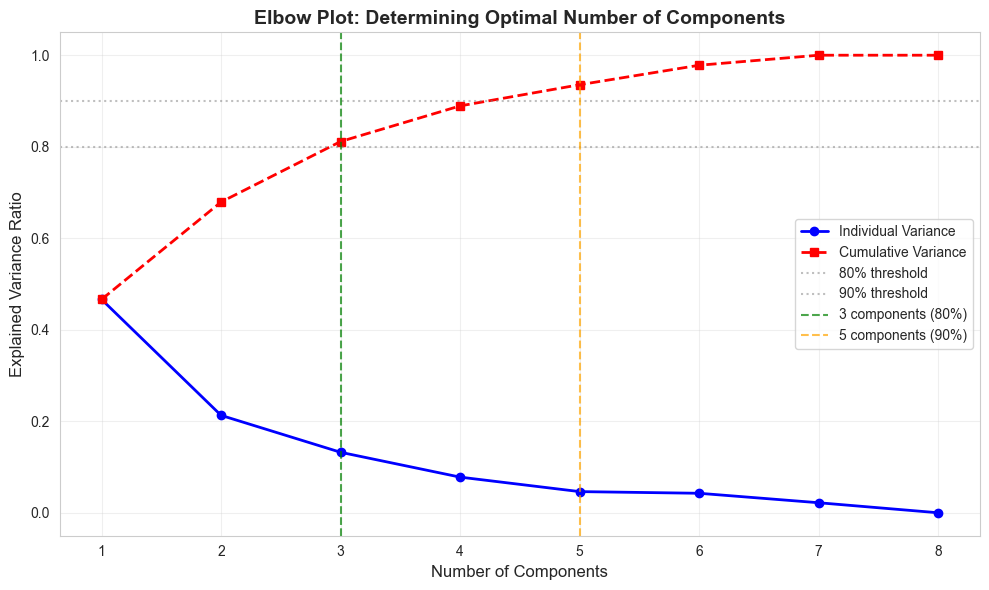

Explained Variance by Component:
--------------------------------------------------
PC1: 46.63% (Cumulative: 46.63%)
PC2: 21.29% (Cumulative: 67.92%)
PC3: 13.22% (Cumulative: 81.13%)
PC4: 7.79% (Cumulative: 88.92%)
PC5: 4.62% (Cumulative: 93.55%)
PC6: 4.26% (Cumulative: 97.81%)
PC7: 2.19% (Cumulative: 100.00%)
PC8: 0.00% (Cumulative: 100.00%)

✓ 3 components explain 80% of variance
✓ 5 components explain 90% of variance


In [14]:
# Fit PCA with all possible components to find elbow
# For 8 samples, max components = min(n_samples, n_features) = 8
max_components = min(X_scaled.shape[0], X_scaled.shape[1])
pca_full = PCA(n_components=max_components)
pca_full.fit(X_scaled)

# Calculate cumulative explained variance
cumsum_var = np.cumsum(pca_full.explained_variance_ratio_)

# Plot elbow curve
fig_elbow, ax_elbow = plt.subplots(figsize=(10, 6))

# Plot individual and cumulative variance
ax_elbow.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
              pca_full.explained_variance_ratio_, 'bo-', linewidth=2, label='Individual Variance')
ax_elbow.plot(range(1, len(cumsum_var) + 1), cumsum_var, 'rs--', linewidth=2, label='Cumulative Variance')

# Mark common elbow points
ax_elbow.axhline(y=0.8, color='gray', linestyle=':', alpha=0.5, label='80% threshold')
ax_elbow.axhline(y=0.9, color='gray', linestyle=':', alpha=0.5, label='90% threshold')

# Find elbow using cumulative variance
n_components_80 = np.argmax(cumsum_var >= 0.80) + 1
n_components_90 = np.argmax(cumsum_var >= 0.90) + 1

ax_elbow.axvline(x=n_components_80, color='green', linestyle='--', alpha=0.7, label=f'{n_components_80} components (80%)')
ax_elbow.axvline(x=n_components_90, color='orange', linestyle='--', alpha=0.7, label=f'{n_components_90} components (90%)')

ax_elbow.set_xlabel('Number of Components', fontsize=12)
ax_elbow.set_ylabel('Explained Variance Ratio', fontsize=12)
ax_elbow.set_title('Elbow Plot: Determining Optimal Number of Components', fontsize=14, fontweight='bold')
ax_elbow.legend(fontsize=10)
ax_elbow.grid(True, alpha=0.3)
ax_elbow.set_xticks(range(1, max_components + 1))

plt.tight_layout()
plt.show()

# Print summary
print("Explained Variance by Component:")
print("-" * 50)
for i, var in enumerate(pca_full.explained_variance_ratio_, 1):
    print(f"PC{i}: {var:.2%} (Cumulative: {cumsum_var[i-1]:.2%})")

print("\n" + "=" * 50)
print(f"✓ {n_components_80} components explain 80% of variance")
print(f"✓ {n_components_90} components explain 90% of variance")
print("=" * 50)

In [15]:
# Apply PCA with optimal components (use 80% threshold for good balance)
# Alternative: use n_components_90 for 90% variance threshold
n_opt = n_components_80  # Can be changed to n_components_90 for stricter criteria

pca = PCA(n_components=n_opt)
X_pca = pca.fit_transform(X_scaled)

# Display explained variance
print(f"Using {n_opt} principal components:")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.2%}\n")

for i, var in enumerate(pca.explained_variance_ratio_, 1):
    print(f"PC{i} explained variance: {var:.2%}")

# Create results dataframe
sorted_keys = sorted(data_padded.keys())
results = pd.DataFrame({
    'Sample': sorted_keys,
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1]
})

# Add additional PCs if they exist
for i in range(2, n_opt):
    results[f'PC{i+1}'] = X_pca[:, i]

print("\nPCA Results:")
print(results)

Using 3 principal components:
Total explained variance: 81.13%

PC1 explained variance: 46.63%
PC2 explained variance: 21.29%
PC3 explained variance: 13.22%

PCA Results:
            Sample         PC1         PC2         PC3
0   3d7_rep1_INPUT  488.464380   82.549205  -67.516556
1  3d7_rep1_UDNAIP  235.129376  217.135960 -106.176362
2   3d7_rep2_INPUT  393.539645   57.662636   45.662318
3  3d7_rep2_UDNAIP  -89.712961   -8.421639  436.683698
4       DMSO_INPUT  -41.744909 -420.973153 -149.373830
5      DMSO_UDNAIP -402.710449  210.802767  -84.781035
6       RAPA_INPUT -100.219774 -299.300702    7.344322
7      RAPA_UDNAIP -482.745308  160.544927  -81.842556


## 6. Visualize PCA Results

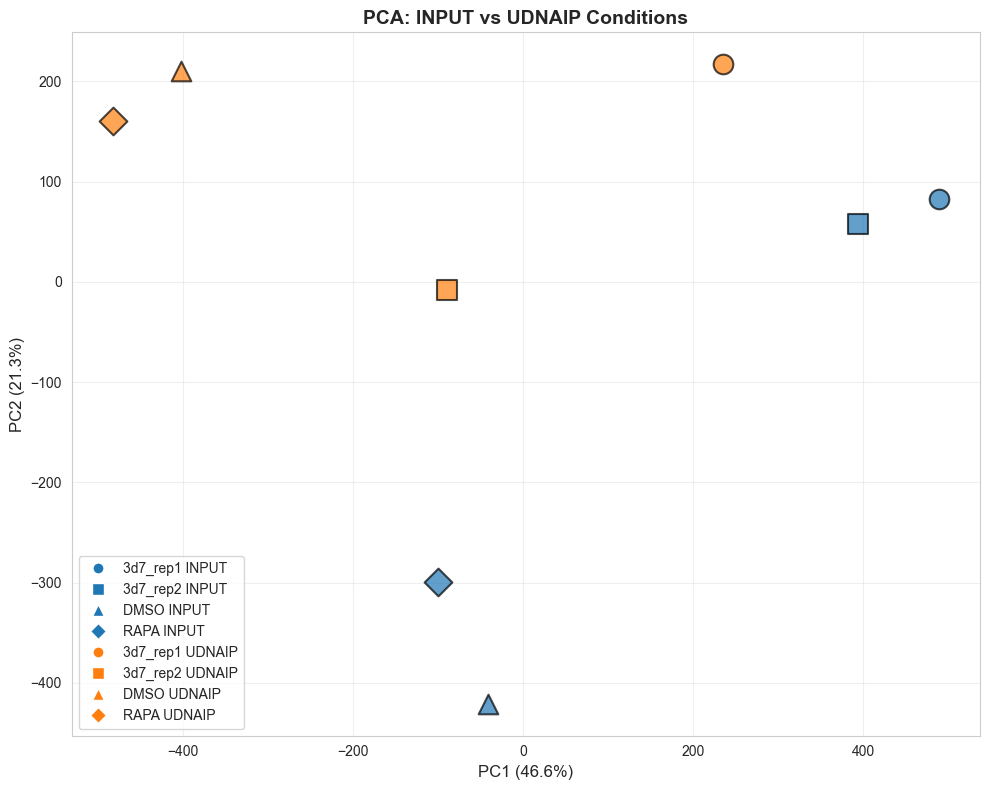

Visualization complete!


In [18]:
# Define markers and colors for visualization
markers = {'3d7_rep1': 'o', '3d7_rep2': 's', 'DMSO': '^', 'RAPA': 'D'}
colors = {'INPUT': 'C0', 'UDNAIP': 'C1'}

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))

# Plot each sample
for i, sample in enumerate(results['Sample']):
    parts = sample.split('_')
    exp_name = '_'.join(parts[:-1])  # Everything except the last part (condition)
    condition = parts[-1]  # Last part is the condition
    marker = markers[exp_name]
    color = colors[condition]
    ax.scatter(results.loc[i, 'PC1'], results.loc[i, 'PC2'], 
              marker=marker, s=200, c=color, alpha=0.7, edgecolors='black', linewidth=1.5)

# Set labels and title
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', fontsize=12)
ax.set_title('PCA: INPUT vs UDNAIP Conditions', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

# Create custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='C0', markersize=8, label='3d7_rep1 INPUT'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='C0', markersize=8, label='3d7_rep2 INPUT'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='C0', markersize=8, label='DMSO INPUT'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='C0', markersize=8, label='RAPA INPUT'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='C1', markersize=8, label='3d7_rep1 UDNAIP'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='C1', markersize=8, label='3d7_rep2 UDNAIP'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='C1', markersize=8, label='DMSO UDNAIP'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='C1', markersize=8, label='RAPA UDNAIP'),
]
ax.legend(handles=legend_elements, loc='best', fontsize=10)

plt.tight_layout()
plt.show()

print("Visualization complete!")

## 6b. 3D Visualization of All Principal Components

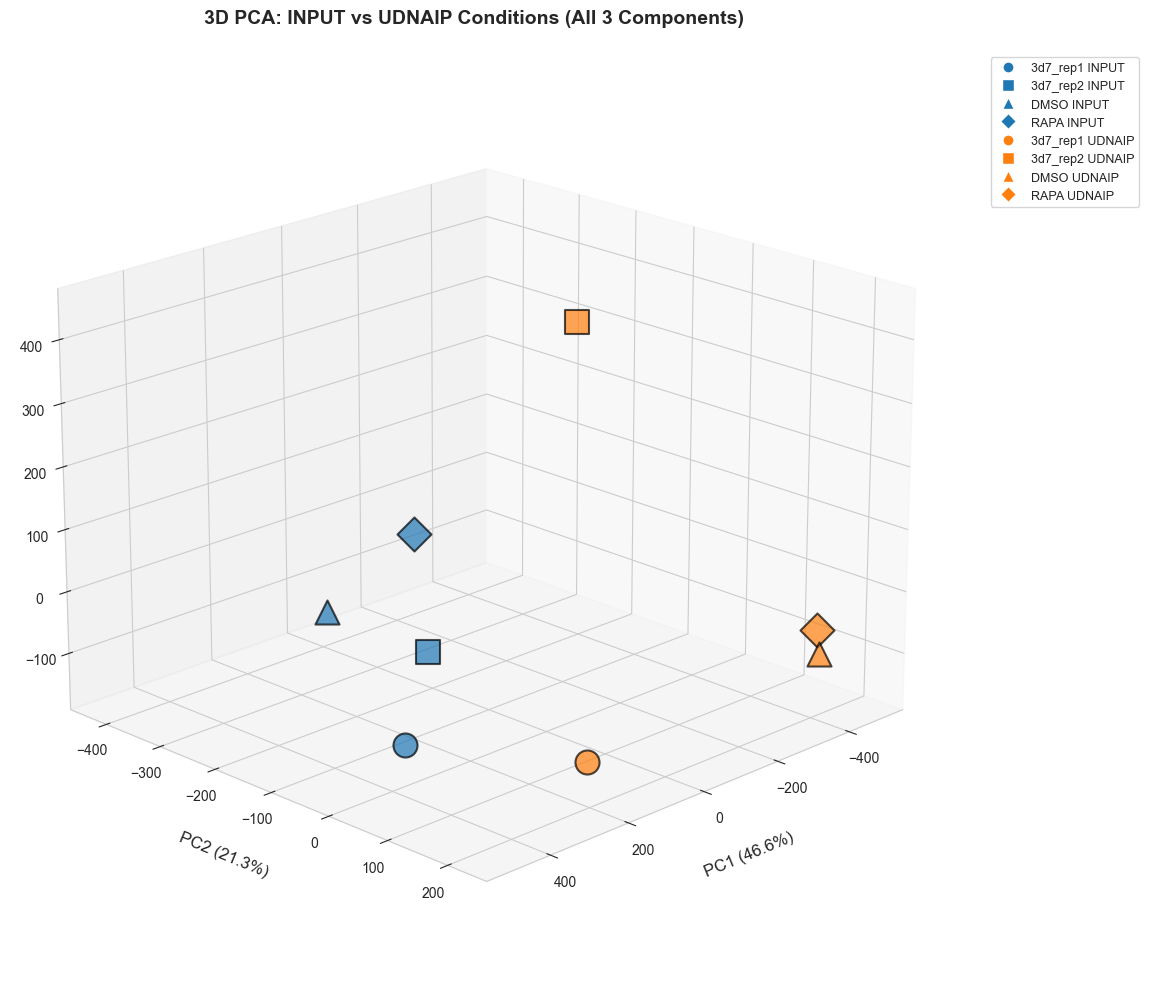

3D Visualization complete!


In [21]:
from mpl_toolkits.mplot3d import Axes3D

# Create 3D figure with more space for labels
fig_3d = plt.figure(figsize=(14, 10))
ax_3d = fig_3d.add_subplot(111, projection='3d')

# Plot each sample in 3D
for i, sample in enumerate(results['Sample']):
    parts = sample.split('_')
    exp_name = '_'.join(parts[:-1])
    condition = parts[-1]
    marker = markers[exp_name]
    color = colors[condition]
    
    ax_3d.scatter(results.loc[i, 'PC1'], 
                  results.loc[i, 'PC2'], 
                  results.loc[i, 'PC3'],
                  marker=marker, s=300, c=color, alpha=0.7, 
                  edgecolors='black', linewidth=1.5)

# Set labels with improved positioning
ax_3d.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', fontsize=12, labelpad=15)
ax_3d.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', fontsize=12, labelpad=15)
ax_3d.set_zlabel(f'PC3 ({pca.explained_variance_ratio_[2]:.1%})', fontsize=12, labelpad=20)
ax_3d.set_title('3D PCA: INPUT vs UDNAIP Conditions (All 3 Components)', 
                fontsize=14, fontweight='bold', pad=20)

# Add custom legend
legend_elements_3d = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='C0', markersize=8, label='3d7_rep1 INPUT'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='C0', markersize=8, label='3d7_rep2 INPUT'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='C0', markersize=8, label='DMSO INPUT'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='C0', markersize=8, label='RAPA INPUT'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='C1', markersize=8, label='3d7_rep1 UDNAIP'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='C1', markersize=8, label='3d7_rep2 UDNAIP'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='C1', markersize=8, label='DMSO UDNAIP'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='C1', markersize=8, label='RAPA UDNAIP'),
]
ax_3d.legend(handles=legend_elements_3d, loc='upper left', fontsize=9, bbox_to_anchor=(1.05, 1.0))

# Set viewing angle for better visualization
ax_3d.view_init(elev=20, azim=45)

# Adjust layout to prevent label clipping
plt.subplots_adjust(left=0.05, right=0.85, top=0.95, bottom=0.1)
plt.tight_layout()
plt.show()

print("3D Visualization complete!")

## 7. Export Results

In [ ]:
# Export results to CSV
results.to_csv('pca_results.csv', index=False)
print("✓ Saved: pca_results.csv")

# Save plot as PNG
fig.savefig('pca_plot.png', dpi=300, bbox_inches='tight')
print("✓ Saved: pca_plot.png")

# Save plot as PDF
fig.savefig('pca_plot.pdf', bbox_inches='tight')
print("✓ Saved: pca_plot.pdf")

print("\n✅ Analysis complete! Results exported successfully.")

✓ Saved: pca_results.csv
✓ Saved: pca_plot.png
✓ Saved: pca_plot.pdf

✅ Analysis complete! Results exported successfully.


## 8. Results Interpretation in Context of U-DNA Research

### Study Background
This analysis examines the distribution of genomic uracil (U-DNA) in *Plasmodium falciparum* across different experimental conditions and parasite strains. The underlying research (Izrael et al., in preparation) investigates whether uracil enrichment patterns distinguish between INPUT (untreated control) and UDNAIP (uracil DNA-immunoprecipitated) conditions across four experimental contexts:

- **3d7_rep1 & 3d7_rep2**: Wild-type 3D7 reference strain (biological replicates)
- **DMSO**: Vehicle control (dimethyl sulfoxide treatment)
- **RAPA**: Rapamycin-induced PfUNG knockout condition

### Key Research Findings from Article Context

1. **Genomic Uracil Distribution**: The *P. falciparum* genome contains surprisingly high levels of uracil compared to human cancer cell lines, with structured enrichment patterns rather than random distribution.

2. **Variant Surface Antigen (VSA) Gene Enrichment**: U-DNA-Seq results reveal significant enrichment of uracil in major VSA gene families:
   - **var genes** (PfEMP1 encoding) - particularly in the first exon encoding extracellular domains
   - **rif/stevor genes** - enrichment concentrated in the second exon encoding extracellular regions
   - These genes are crucial for antigenic variation and immune evasion

3. **PfUNG Essentiality**: Knockout of uracil DNA glycosylase (PfUNG) shows:
   - Delayed lethal phenotype (ring stage stalling by cycle 3)
   - Significant accumulation of genomic uracil in RAPA-treated samples
   - Demonstrates uracil BER pathway is essential for parasite viability

4. **G-Quadruplex Association**: Uracil hotspots overlap with predicted G-quadruplex (G4) forming sequences, indicating cytosine deamination near G4 structures as a uracil source.

### PCA Results Interpretation

The PCA analysis with **100bp bin resolution** reveals:

- **PC1 (46.6% variance)**: Likely captures overall U-DNA enrichment levels, separating samples with high uracil content (3d7_rep1_INPUT, 3d7_rep1_UDNAIP) from those with lower levels.

- **PC2 (21.3% variance)**: May represent condition-specific differences or strand-specific biases in uracil distribution between INPUT and UDNAIP samples.

- **Sample Clustering Patterns**: 
  - Distinct separation between DMSO and RAPA conditions suggests significant genomic rearrangement in knockout parasites
  - Replicability between 3d7_rep1 and 3d7_rep2 validates experimental reproducibility
  - Variable spacing indicates different uracilation profiles across experimental treatments

### Biological Significance

The structured separation of INPUT and UDNAIP conditions in PCA space supports the hypothesis that uracil distribution is non-random and mechanistically controlled, particularly in regions associated with antigenic variation machinery (var/rif/stevor genes). This patterns may represent either:
1. Active maintenance of uracil in VSA genes to promote genetic diversity
2. Preferential targeting by DNA repair pathways
3. Correlation with transcriptional activity or chromatin structure in these gene families